In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os
import json
import sys

sys.path.append("../")

##################################################################
os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "0,1,3,4,5,6,7"
##################################################################

import logging
from src.utils import logging_utils
from src.utils import env_utils, experiment_utils
import torch
import transformers
from rich.console import Console
from rich.theme import Theme
import nnsight

experiment_utils.set_seed(42)

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, width=300)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logger = logging.getLogger(__name__)

logging.basicConfig(
    level=logging.DEBUG,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)

logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(
    f"{torch.cuda.is_available()=}, {torch.cuda.device_count()=}, {torch.cuda.get_device_name()=}"
)
logger.info(f"{transformers.__version__=}")
logger.info(f"{nnsight.__version__}")


2026-03-02 15:31:16 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-03-02 15:31:16 __main__ INFO     torch.cuda.is_available()=True, torch.cuda.device_count()=7, torch.cuda.get_device_name()='NVIDIA A100 80GB PCIe'
2026-03-02 15:31:16 __main__ INFO     transformers.__version__='5.1.0'
2026-03-02 15:31:16 __main__ INFO     0.5.15


## Load Model

In [3]:
from src.models import ModelandTokenizer

# model_key = "Qwen/Qwen2.5-Coder-14B-Instruct"
# model_key = "Qwen/Qwen2.5-Coder-32B"
model_key = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=model_key,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)


2026-03-02 15:31:17 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-03-02 15:31:17 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-02 15:31:17 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe516d547a0>
2026-03-02 15:31:17 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe51769d350> server_hostname='huggingface.co' timeout=10
2026-03-02 15:31:17 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe517500c20>
2026-03-02 15:31:17 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-02 15:31:17 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-02 15:31:17 http

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-03-02 15:31:37 httpcore.connection DEBUG    close.started
2026-03-02 15:31:37 httpcore.connection DEBUG    close.complete
2026-03-02 15:31:37 httpcore.connection DEBUG    connect_tcp.started host='huggingface.co' port=443 local_address=None timeout=10 socket_options=None
2026-03-02 15:31:37 httpcore.connection DEBUG    connect_tcp.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe5156dbad0>
2026-03-02 15:31:37 httpcore.connection DEBUG    start_tls.started ssl_context=<ssl.SSLContext object at 0x7fe51769d350> server_hostname='huggingface.co' timeout=10
2026-03-02 15:31:37 httpcore.connection DEBUG    start_tls.complete return_value=<httpcore._backends.sync.SyncStream object at 0x7fe5156dbe60>
2026-03-02 15:31:37 httpcore.http11 DEBUG    send_request_headers.started request=<Request [b'HEAD']>
2026-03-02 15:31:37 httpcore.http11 DEBUG    send_request_headers.complete
2026-03-02 15:31:37 httpcore.http11 DEBUG    send_request_body.started request=<Request [b'HE

## Load Multi-Predicate Data

In [6]:
from src.goals.predicate_data import MultiPredicateDataset
from src.goals.predicate_sampling import MCTSSearchResults_for_TargetPredicate

# ── Select target predicate ──────────────────────────────────────────────────
PREDICATE_IDX = 2

eval_dataset = MultiPredicateDataset.load_dataset()
target_predicate = eval_dataset[PREDICATE_IDX]
rich_print(f"Target predicate : [cyan]{target_predicate.name}[/cyan]")
rich_print(f"P+ : [bold green]{target_predicate.p_plus.description}[/bold green]  anchors={target_predicate.p_plus.anchor_tokens}")
for i, s in enumerate(target_predicate.samples):
    p_minus_desc = s.p_minus.description if s.p_minus else "(none)"
    rich_print(f"  Sample {i} — fn=[yellow]{s.function_name}[/yellow]  P-: {p_minus_desc}")


2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'has_unique_elements' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/has_unique_elements.json
2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_anagram' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_anagram.json


2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_palindrome' with 5 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_palindrome.json
2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_perfect_square' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_perfect_square.json
2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_power_of_two' with 3 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_power_of_two.json
2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded TargetPredicate 'is_sorted' with 4 sample(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate/is_sorted.json
2026-03-02 11:32:54 src.goals.predicate_data INFO     Loaded MultiPredicateDataset: 6 target predicate(s) from /disk/u/arnab/Codes/Projects/goals/data/multi_predicate


Target predicate : is_palindrome

P+ : check whether s is a palindrome (s == s[::-1])  anchors=['== s.lower()[::-1]', '== s[::-1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's[-1:-3:-1]', 's[-i-1]', 's[::- 1]', 's[::-1]']

Sample 0 — fn=is_valid_palindrome  P-: check whether len(s) >= 2

Sample 1 — fn=is_alpha_palindrome  P-: check whether s.isalpha() (all characters are alphabetic)

Sample 2 — fn=is_spaceless_palindrome  P-: check whether ' ' not in s (no spaces)

Sample 3 — fn=is_upper_palindrome  P-: check whether s is non-empty and s[0].isupper()

Sample 4 — fn=is_lowercase_palindrome  P-: check whether s == s.lower() (all lowercase)

In [7]:
model_tag = mt.name.split("/")[-1]
SAVE_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "MultiPredicate_MCTS",
    model_tag,
    f"{target_predicate.name}.json",
)

if not os.path.exists(SAVE_PATH):
    raise FileNotFoundError(
        f"No MCTS results found at {SAVE_PATH}.\n"
        "Run the MCTS sampling notebook (02.1_multi_pred_sampling) first."
    )

tp_results = MCTSSearchResults_for_TargetPredicate.load(SAVE_PATH)
rich_print(f"Loaded [bold]{len(tp_results.sample_results)}[/bold] sample results from {SAVE_PATH}")
for i, sr in enumerate(tp_results.sample_results):
    counts = [run.eval_counts for run in sr.runs]
    rich_print(f"  Sample {i} — {len(sr.runs)} runs  eval_counts={counts}")


2026-03-02 11:33:00 src.goals.predicate_sampling INFO     Loaded MCTSSearchResults for 'is_palindrome' (5 sample(s)) from /disk/u/arnab/Codes/Projects/goals/results/MultiPredicate_MCTS/Qwen2.5-Coder-32B-Instruct/is_palindrome.json


Loaded 5 sample results from /disk/u/arnab/Codes/Projects/goals/results/MultiPredicate_MCTS/Qwen2.5-Coder-32B-Instruct/is_palindrome.json

Sample 0 — 10 runs  eval_counts=[{'green': 10, 'orange': 9, 'red': 3, 'total': 22}, {'green': 18, 'orange': 0, 'red': 4, 'total': 22}, {'green': 28, 'orange': 128, 'red': 4, 'total': 160}, {'green': 10, 'orange': 7, 'red': 2, 'total': 19}, {'green': 31, 'orange': 56, 'red': 28, 'total': 115}, 
{'green': 4, 'orange': 0, 'red': 5, 'total': 9}, {'green': 10, 'orange': 2, 'red': 5, 'total': 17}, {'green': 8, 'orange': 0, 'red': 6, 'total': 14}, {'green': 18, 'orange': 68, 'red': 18, 'total': 104}, {'green': 10, 'orange': 13, 'red': 4, 'total': 27}]

Sample 1 — 10 runs  eval_counts=[{'green': 6, 'orange': 22, 'red': 0, 'total': 28}, {'green': 7, 'orange': 9, 'red': 6, 'total': 22}, {'green': 14, 'orange': 20, 'red': 0, 'total': 34}, {'green': 6, 'orange': 15, 'red': 2, 'total': 23}, {'green': 13, 'orange': 2, 'red': 6, 'total': 21}, {'green': 
14, 'orange': 2, 'red': 2, 'total': 18}, {'green': 54, 'orange': 248, 'red': 11, 'total': 313}, {'green': 8, 'orange': 4, 'red': 1, 'total': 13}, {'green': 2, 'orange': 69, 'red': 2, 'total': 73}, {'green': 6, 'orange': 6, 'red': 2, 'total': 14}]

Sample 2 — 10 runs  eval_counts=[{'green': 14, 'orange': 13, 'red': 3, 'total': 30}, {'green': 12, 'orange': 8, 'red': 10, 'total': 30}, {'green': 50, 'orange': 58, 'red': 11, 'total': 119}, {'green': 14, 'orange': 5, 'red': 3, 'total': 22}, {'green': 4, 'orange': 0, 'red': 6, 'total': 10}, 
{'green': 4, 'orange': 0, 'red': 6, 'total': 10}, {'green': 76, 'orange': 25, 'red': 24, 'total': 125}, {'green': 6, 'orange': 0, 'red': 2, 'total': 8}, {'green': 32, 'orange': 30, 'red': 9, 'total': 71}, {'green': 4, 'orange': 0, 'red': 12, 'total': 16}]

Sample 3 — 11 runs  eval_counts=[{'green': 18, 'orange': 30, 'red': 2, 'total': 50}, {'green': 6, 'orange': 30, 'red': 6, 'total': 42}, {'green': 18, 'orange': 22, 'red': 0, 'total': 40}, {'green': 16, 'orange': 21, 'red': 0, 'total': 37}, {'green': 2, 'orange': 15, 'red': 9, 'total': 26}, 
{'green': 0, 'orange': 8, 'red': 2, 'total': 10}, {'green': 6, 'orange': 20, 'red': 2, 'total': 28}, {'green': 44, 'orange': 43, 'red': 7, 'total': 94}, {'green': 36, 'orange': 4, 'red': 5, 'total': 45}, {'green': 8, 'orange': 60, 'red': 7, 'total': 75}, {'green': 20, 'orange': 21, 'red': 7, 
'total': 48}]

Sample 4 — 11 runs  eval_counts=[{'green': 14, 'orange': 8, 'red': 0, 'total': 22}, {'green': 18, 'orange': 15, 'red': 6, 'total': 39}, {'green': 8, 'orange': 23, 'red': 3, 'total': 34}, {'green': 8, 'orange': 7, 'red': 2, 'total': 17}, {'green': 8, 'orange': 2, 'red': 2, 'total': 12}, {'green': 
28, 'orange': 28, 'red': 6, 'total': 62}, {'green': 0, 'orange': 6, 'red': 6, 'total': 12}, {'green': 178, 'orange': 91, 'red': 18, 'total': 287}, {'green': 34, 'orange': 16, 'red': 0, 'total': 50}, {'green': 64, 'orange': 27, 'red': 1, 'total': 92}, {'green': 18, 'orange': 17, 'red': 1, 'total': 
36}]

## Collect Contrastive Pairs

In [8]:
from src.goals.predicate_probe import (
    collect_labeled_nodes,
    sample_multipred_pairs,
    print_node_label_summary,
    print_pairs_sample,
    pairs_position_histogram,
)

# min_p_green: only keep nodes where at least this fraction of MCTS probability
# mass flows to green (correct) leaves.  Filters out nodes that are on a green
# path by luck but where the model's probability mass mostly flows to failures.
# Set to 0.0 to disable.
MIN_P_GREEN = 0.5

labeled = collect_labeled_nodes(
    tp_results=tp_results,
    tp=target_predicate,
    mt=mt,
    min_p_green=MIN_P_GREEN,
)

print_node_label_summary(labeled)


2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 's == s': 10 green leaves → 88 labeled nodes (2 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 's[::-1]': 18 green leaves → 80 labeled nodes (0 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 's[:': 28 green leaves → 172 labeled nodes (54 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 's ==': 10 green leaves → 46 labeled nodes (0 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 'len(': 31 green leaves → 390 labeled nodes (0 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 'len(s)': 4 green leaves → 40 labeled nodes (0 dropped by p_green < 0.5).
2026-03-02 11:33:12 src.goals.predicate_probe DEBUG    Sample 0, prefill 'not (': 10 green leaves → 128 labeled node

                   Labeled Node Summary                    
                                                           
  label        window     prefill_type              count  
 ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 
  p_minus      first      adversarial                3324  
  p_minus      first      aligned_p_minus             303  
  p_minus      first      aligned_p_plus              198  
  p_minus      first      inconsequential             350  
  p_minus      second     adversarial                 294  
  p_minus      second     aligned_p_plus             1028  
  p_minus      second     inconsequential             100  
  p_plus       first      adversarial                 334  
  p_plus       first      aligned_p_plus              521  
  p_plus       first      inconsequential              58  
  p_plus       second     adversarial                2018  
  p_plus       second     aligned_p_minus             616  
  p_plus       second     aligned_p_plus              270  
  p_plus       second     inconsequential             280

Total: 9694 nodes  |  p_plus=4097  p_minus=5597  |  45 trees  |  38 distinct abs_positions

In [9]:
# ── Form cross-tree contrastive pairs ────────────────────────────────────────
# allow_same_tree=False (default): only pair nodes from different prefill trees.
# abs_pos_tolerance=0: require exact absolute position match.
# Increase tolerance to 1-2 if prefill lengths vary by ±1 token and pair counts are low.
pairs_by_pos = sample_multipred_pairs(
    labeled_nodes=labeled,
    allow_same_tree=False,
    abs_pos_tolerance=0,
)

pairs_position_histogram(pairs_by_pos)
print_pairs_sample(pairs_by_pos, n=6)


2026-03-02 11:33:41 src.goals.predicate_probe INFO     sample_multipred_pairs: 4065 pairs across 33 positions.


Pair count by absolute token position:

101  █ 10

102  ███ 20

103  ██████ 36

104  ███████ 42

... (45 outputs left out)

abs_pos=101  (pos depth=1, 'aligned_p_plus'  |  neg depth=1, 'inconsequential')

+ first ']=='

- first ' all'

... 4059 more pairs not shown

In [10]:
import random
from collections import defaultdict

# ── Build lookup: prefix → prompt (needed to reconstruct full input text) ────
prefix_to_prompt = {
    run.prefix: run.prompt
    for sr in tp_results.sample_results
    for run in sr.runs
}

# ── Flatten pairs into records ────────────────────────────────────────────────
# Each record: pos_text / neg_text to feed the model + metadata for analysis.
all_pairs = [pair for pairs in pairs_by_pos.values() for pair in pairs]

pair_records = []
for pair in all_pairs:
    pos_ln = pair.positive
    neg_ln = pair.negative
    pos_prompt = prefix_to_prompt.get(pos_ln.tree_id, "")
    neg_prompt = prefix_to_prompt.get(neg_ln.tree_id, "")
    pair_records.append({
        "pos_text":       pos_prompt + pos_ln.node.get_path_text(),
        "neg_text":       neg_prompt + neg_ln.node.get_path_text(),
        "abs_position":   pair.abs_position,
        "pos_depth":      pos_ln.depth,
        "neg_depth":      neg_ln.depth,
        "pos_window":     pos_ln.window,
        "neg_window":     neg_ln.window,
        "pos_tree_id":    pos_ln.tree_id,
        "neg_tree_id":    neg_ln.tree_id,
        "pos_prefill_type": pos_ln.prefill_type,
        "neg_prefill_type": neg_ln.prefill_type,
        "sample_idx":     pos_ln.sample_idx,
    })

rich_print(f"Total pair records: [bold]{len(pair_records)}[/bold]")


Total pair records: 4065

In [11]:
# ── Train / test split by tree (prevents latent leakage across the split) ────
# Assign each pair based on the positive node's source tree.
# Trees (prefills) are the natural unit of independence here.
N_TRAIN_PAIRS = 10_000   # max pairs in train set; None = use all
N_TEST_PAIRS  = None     # max pairs in test set;  None = use all

random.seed(42)
all_tree_ids = list({rec["pos_tree_id"] for rec in pair_records})
random.shuffle(all_tree_ids)
n_train_trees = max(1, int(0.8 * len(all_tree_ids)))
train_trees = set(all_tree_ids[:n_train_trees])
test_trees  = set(all_tree_ids[n_train_trees:])

train_idx = [i for i, r in enumerate(pair_records) if r["pos_tree_id"] in train_trees]
test_idx  = [i for i, r in enumerate(pair_records) if r["pos_tree_id"] in test_trees]

if N_TRAIN_PAIRS is not None and len(train_idx) > N_TRAIN_PAIRS:
    train_idx = random.sample(train_idx, N_TRAIN_PAIRS)
if N_TEST_PAIRS is not None and len(test_idx) > N_TEST_PAIRS:
    test_idx = random.sample(test_idx, N_TEST_PAIRS)

n_pairs_total = len(pair_records)
rich_print(
    f"Split: [bold]{len(train_idx)}[/bold] train / [bold]{len(test_idx)}[/bold] test  "
    f"({len(train_trees)} train trees / {len(test_trees)} test trees)"
)


Split: 3497 train / 568 test  (33 train trees / 9 test trees)

## Extract Latents

In [12]:
from src.tokens import prepare_input

@torch.inference_mode()
def get_last_token_latents_batch(
    mt: ModelandTokenizer,
    texts: list[str],
    layers: list[int] | None = None,
) -> dict[int, torch.Tensor]:
    """
    Extract residual stream hidden states at the last token position for a batch of inputs.

    Simplified and batched — no interventions, grabs the last non-padding token's
    residual stream across specified layers.  Each layer stays on its native GPU.

    Args:
        mt:     ModelandTokenizer instance.
        texts:  List of input strings.
        layers: Layer indices to extract. None = all layers.

    Returns:
        Dict mapping layer_idx -> Tensor of shape (batch, hidden_dim).
    """
    if layers is None:
        layers = list(range(mt.n_layer))

    inputs = prepare_input(prompts=texts, tokenizer=mt, padding_side="left")

    layer_saves = {}
    with mt.trace(inputs, scan=False):
        for layer_idx in layers:
            layer_name = mt.layer_name_format.format(layer_idx)
            module = mt
            for attr in layer_name.split("."):
                module = module[int(attr)] if attr.isdigit() else getattr(module, attr)
            output = module.output
            if isinstance(output, tuple) or (hasattr(output, "__len__") and not hasattr(output, "shape")):
                output = output[0]
            layer_saves[layer_idx] = output[:, -1, :].save()

    return {l: layer_saves[l].float() for l in layers}


# Quick sanity check
_sample_texts = [pair_records[0]["pos_text"], pair_records[0]["neg_text"]]
_test_hs = get_last_token_latents_batch(mt, _sample_texts, layers=[0, mt.n_layer - 1])
for l, t in _test_hs.items():
    rich_print(f"Layer {l}: shape={list(t.shape)}, device={t.device}")


Layer 0: shape=[2, 5120], device=cuda:0

Layer 63: shape=[2, 5120], device=cuda:5

In [13]:
LAYERS_TO_PROBE = list(range(mt.n_layer))
BATCH_SIZE = 32

pos_texts = [pair_records[i]["pos_text"] for i in range(n_pairs_total)]
neg_texts = [pair_records[i]["neg_text"] for i in range(n_pairs_total)]
all_texts = pos_texts + neg_texts  # 2 * n_pairs_total

n_total = len(all_texts)
rich_print(f"Extracting latents for {n_total} texts ({n_pairs_total} pairs) in batches of {BATCH_SIZE}...")

latents_by_layer: dict[int, list[torch.Tensor]] = {l: [] for l in LAYERS_TO_PROBE}

for batch_start in range(0, n_total, BATCH_SIZE):
    batch_texts = all_texts[batch_start : batch_start + BATCH_SIZE]
    if batch_start % (BATCH_SIZE * 10) == 0:
        rich_print(f"  Batch {batch_start // BATCH_SIZE + 1}/{(n_total + BATCH_SIZE - 1) // BATCH_SIZE}...")
    batch_hs = get_last_token_latents_batch(mt, batch_texts, layers=LAYERS_TO_PROBE)
    for l in LAYERS_TO_PROBE:
        latents_by_layer[l].append(batch_hs[l])

Z_pos_by_layer: dict[int, torch.Tensor] = {}
Z_neg_by_layer: dict[int, torch.Tensor] = {}

for l in LAYERS_TO_PROBE:
    all_l = torch.cat(latents_by_layer[l], dim=0)   # (2*n_pairs_total, hidden_dim)
    Z_pos_by_layer[l] = all_l[:n_pairs_total]
    Z_neg_by_layer[l] = all_l[n_pairs_total:]

rich_print(f"Done. Z_pos shape (layer 0): {list(Z_pos_by_layer[0].shape)}")


Extracting latents for 8130 texts (4065 pairs) in batches of 32...

Batch 1/255...

Batch 11/255...

Batch 21/255...

Batch 31/255...

Batch 41/255...

... (18 outputs left out)

Batch 231/255...

Batch 241/255...

Batch 251/255...

Done. Z_pos shape (layer 0): [4065, 5120]

In [14]:
# ── (Optional) Save / reload latents to avoid re-extracting ─────────────────
model_short_name = mt.name.split("/")[-1]
save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multi_probe",
    model_short_name,
    target_predicate.name,
)
os.makedirs(save_dir, exist_ok=True)

# torch.save(Z_pos_by_layer, os.path.join(save_dir, "Z_pos_by_layer.pt"))
# torch.save(Z_neg_by_layer, os.path.join(save_dir, "Z_neg_by_layer.pt"))

# Z_pos_by_layer = torch.load(os.path.join(save_dir, "Z_pos_by_layer.pt"))
# Z_neg_by_layer = torch.load(os.path.join(save_dir, "Z_neg_by_layer.pt"))
rich_print(f"Save dir: {save_dir}")


Save dir: /disk/u/arnab/Codes/Projects/goals/results/multi_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

## Analysis of the Latents
### PCA (without goal-specific engineering)

In [22]:
from sklearn.decomposition import PCA
import numpy as np

LAYER_FROM = 0
LAYER_TO   = mt.n_layer
LAYER_STEP = 4

pca_layers = list(range(LAYER_FROM, LAYER_TO, LAYER_STEP))
pca_results: dict[int, dict] = {}

for layer_idx in pca_layers:
    z_pos = Z_pos_by_layer[layer_idx].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx].cpu().numpy()
    n = z_pos.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    pca = PCA(n_components=2)
    all_2d = pca.fit_transform(all_z)

    pca_results[layer_idx] = {
        "pos_2d": all_2d[:n],
        "neg_2d": all_2d[n:],
        "explained_variance_ratio": pca.explained_variance_ratio_,
    }

rich_print(f"Computed PCA for {len(pca_layers)} layers: {pca_layers[0]}..{pca_layers[-1]} (step={LAYER_STEP})")
rich_print(f"Latents per layer: {n} pos (P+) + {n} neg (P-) = {2*n}")


Computed PCA for 16 layers: 0..60 (step=4)

Latents per layer: 4065 pos (P+) + 4065 neg (P-) = 8130

In [23]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
from IPython.display import HTML

fig, ax = plt.subplots(figsize=(8, 7))

all_x = np.concatenate([np.concatenate([r["pos_2d"][:, 0], r["neg_2d"][:, 0]]) for r in pca_results.values()])
all_y = np.concatenate([np.concatenate([r["pos_2d"][:, 1], r["neg_2d"][:, 1]]) for r in pca_results.values()])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05
xlim = (all_x.min() - pad_x, all_x.max() + pad_x)
ylim = (all_y.min() - pad_y, all_y.max() + pad_y)

neg_scatter = ax.scatter([], [], alpha=0.15, s=6, c="tab:red",  label="P- pursuing")
pos_scatter = ax.scatter([], [], alpha=0.15, s=6, c="tab:blue", label="P+ pursuing")
ax.legend(markerscale=4, loc="upper right")
ax.set_xlim(xlim); ax.set_ylim(ylim)
title = ax.set_title("")

FIGURE_DIR = os.path.join(save_dir, "figures")
os.makedirs(FIGURE_DIR, exist_ok=True)

model_short = mt.name.split("/")[-1]

def update(frame_idx):
    layer_idx = pca_layers[frame_idx]
    r = pca_results[layer_idx]
    evr = r["explained_variance_ratio"]
    pos_scatter.set_offsets(r["pos_2d"])
    neg_scatter.set_offsets(r["neg_2d"])
    ax.set_xlabel(f"PC1 ({evr[0]:.1%} var)")
    ax.set_ylabel(f"PC2 ({evr[1]:.1%} var)")
    title.set_text(f"Layer {layer_idx} | {model_short} | {target_predicate.name} | P+ vs P-")
    return pos_scatter, neg_scatter, title

anim = animation.FuncAnimation(fig, update, frames=len(pca_layers), interval=200, blit=False)
anim.save(os.path.join(FIGURE_DIR, "pca.gif"), writer="pillow", fps=2, dpi=120)
plt.close(fig)
HTML(anim.to_jshtml())


2026-03-02 13:26:38 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>
2026-03-02 13:26:41 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>
2026-03-02 13:26:41 matplotlib.animation DEBUG    frame size in pixels is 800 x 700
2026-03-02 13:26:42 matplotlib.animation DEBUG    MovieWriter: clearing temporary path=<TemporaryDirectory '/tmp/tmpfkt8p6h5'>


## Train Goal Directions

In [17]:
import numpy as np

n_pairs = n_pairs_total
n_layers = len(LAYERS_TO_PROBE)

rich_print(f"Train pairs: {len(train_idx)}, Test pairs: {len(test_idx)}")

# ── Baseline: mean difference direction ─────────────────────────────────────
goal_directions: dict[int, torch.Tensor] = {}
train_accuracies: dict[int, float] = {}
test_accuracies: dict[int, float] = {}

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]

    z_pos_train = z_pos_l[train_idx]
    z_neg_train = z_neg_l[train_idx]

    v_l = z_pos_train.mean(dim=0) - z_neg_train.mean(dim=0)
    v_l = v_l / (v_l.norm() + 1e-8)
    goal_directions[layer_idx] = v_l

    train_acc = (z_pos_train @ v_l > z_neg_train @ v_l).float().mean().item()
    train_accuracies[layer_idx] = train_acc

    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    test_acc = (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    test_accuracies[layer_idx] = test_acc

rich_print(f"\n{'Layer':>6} {'Train':>8} {'Test':>8} {'Device':>12}")
rich_print(f"{'-----':>6} {'-----':>8} {'-----':>8} {'------':>12}")
for l in LAYERS_TO_PROBE:
    marker = " [bold green]<--[/bold green]" if test_accuracies[l] >= 0.8 else ""
    rich_print(f"{l:>6} {train_accuracies[l]:>8.3f} {test_accuracies[l]:>8.3f} {str(z_pos_l.device):>12}{marker}")


Train pairs: 3497, Test pairs: 568

Layer    Train     Test       Device

-----    -----    -----       ------

0    0.879    0.796       cuda:5

1    0.878    0.789       cuda:5

2    0.876    0.790       cuda:5

... (57 outputs left out)

60    0.937    0.810       cuda:5 <--

61    0.937    0.813       cuda:5 <--

62    0.933    0.801       cuda:5 <--

63    0.941    0.824       cuda:5 <--

In [18]:
# ── Contrastive objective (Schut et al. Section 4.1.2) ──────────────────────
# min  λ₁||v||₁ + λ₂||v||₂² + (1/N) Σᵢ max(0, margin - v·(z⁺ᵢ - z⁻ᵢ))

@torch.enable_grad()
def learn_contrastive_direction(
    z_pos: torch.Tensor,
    z_neg: torch.Tensor,
    l1_lambda: float = 0.0,
    l2_lambda: float = 1e-3,
    margin: float = 1.0,
    lr: float = 1e-2,
    n_steps: int = 1000,
    patience: int = 50,
) -> tuple[torch.Tensor, dict]:
    device = z_pos.device
    hidden_dim = z_pos.shape[1]
    delta = z_pos - z_neg

    v = torch.randn(hidden_dim, device=device, dtype=z_pos.dtype) * 0.01
    v.requires_grad_(True)
    optimizer = torch.optim.Adam([v], lr=lr)

    best_loss = float("inf")
    patience_counter = 0
    final_step = n_steps

    for step in range(n_steps):
        optimizer.zero_grad()
        margins = margin - (delta @ v)
        hinge = torch.clamp(margins, min=0).mean()
        l1 = l1_lambda * v.abs().mean()
        l2 = l2_lambda * (v ** 2).mean()
        loss = hinge + l1 + l2
        loss.backward()
        optimizer.step()

        if loss.item() < best_loss:
            best_loss = loss.item()
            patience_counter = 0
        else:
            patience_counter += 1
            if patience_counter >= patience:
                final_step = step + 1
                break

    with torch.no_grad():
        v_norm = v / (v.norm() + 1e-8)

    sparsity = (v_norm.abs() < 0.01).float().mean().item()
    return v_norm.detach(), {"steps": final_step, "best_loss": best_loss, "sparsity": sparsity}


In [19]:
L1_LAMBDA = 0.0
L2_LAMBDA = 1e-3
MARGIN    = 1.0
LR        = 1e-2
N_STEPS   = 1000

contrastive_directions: dict[int, torch.Tensor] = {}
contrastive_train_accs: dict[int, float] = {}
contrastive_test_accs:  dict[int, float] = {}
contrastive_infos:      dict[int, dict]  = {}

reg_desc = []
if L1_LAMBDA > 0: reg_desc.append(f"λ₁={L1_LAMBDA}")
if L2_LAMBDA > 0: reg_desc.append(f"λ₂={L2_LAMBDA}")
if not reg_desc: reg_desc.append("no regularization")
rich_print(f"Learning contrastive directions for {n_layers} layers ({', '.join(reg_desc)}, margin={MARGIN})...")

for layer_idx in LAYERS_TO_PROBE:
    z_pos_l = Z_pos_by_layer[layer_idx]
    z_neg_l = Z_neg_by_layer[layer_idx]

    v_l, info = learn_contrastive_direction(
        z_pos_l[train_idx], z_neg_l[train_idx],
        l1_lambda=L1_LAMBDA, l2_lambda=L2_LAMBDA,
        margin=MARGIN, lr=LR, n_steps=N_STEPS,
    )
    contrastive_directions[layer_idx] = v_l
    contrastive_infos[layer_idx] = info

    contrastive_train_accs[layer_idx] = (
        (z_pos_l[train_idx] @ v_l > z_neg_l[train_idx] @ v_l).float().mean().item()
    )
    z_pos_test = z_pos_l[test_idx]
    z_neg_test = z_neg_l[test_idx]
    contrastive_test_accs[layer_idx] = (
        (z_pos_test @ v_l > z_neg_test @ v_l).float().mean().item()
    )

    if layer_idx % 10 == 0:
        rich_print(
            f"  Layer {layer_idx:>3}: test_acc={contrastive_test_accs[layer_idx]:.3f}, "
            f"steps={info['steps']}, sparsity={info['sparsity']:.3f}"
        )


Learning contrastive directions for 64 layers (λ₂=0.001, margin=1.0)...

Layer   0: test_acc=0.956, steps=439, sparsity=0.624

Layer  10: test_acc=0.961, steps=195, sparsity=0.348

Layer  20: test_acc=0.967, steps=139, sparsity=0.479

Layer  30: test_acc=0.967, steps=104, sparsity=0.391

Layer  40: test_acc=0.977, steps=99, sparsity=0.497

Layer  50: test_acc=0.974, steps=94, sparsity=0.487

Layer  60: test_acc=0.975, steps=100, sparsity=0.460

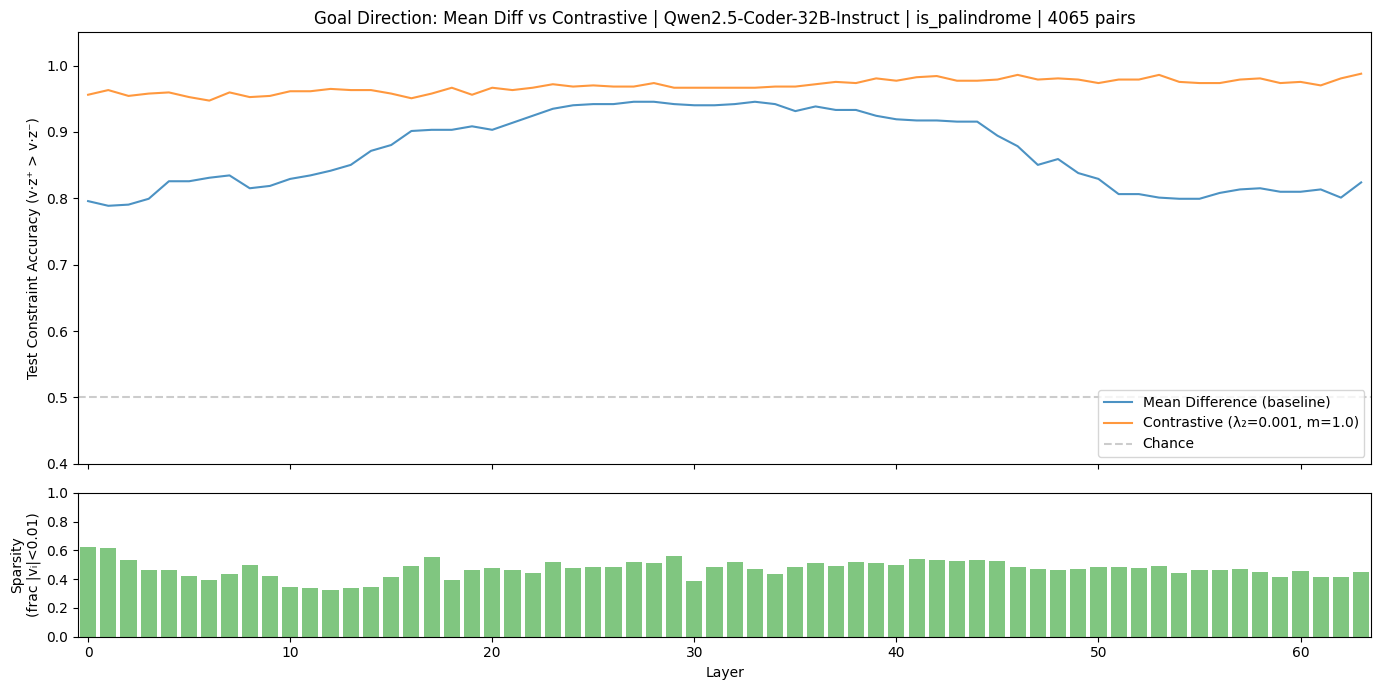

In [24]:
import matplotlib.pyplot as plt

layers_sorted = sorted(LAYERS_TO_PROBE)
md_test = [test_accuracies[l]           for l in layers_sorted]
ct_test = [contrastive_test_accs[l]     for l in layers_sorted]
ct_sparsity = [contrastive_infos[l]["sparsity"] for l in layers_sorted]
reg_label = ", ".join(reg_desc)

fig, axes = plt.subplots(2, 1, figsize=(14, 7), gridspec_kw={"height_ratios": [3, 1]}, sharex=True)

ax = axes[0]
ax.plot(layers_sorted, md_test, label="Mean Difference (baseline)", alpha=0.8, linewidth=1.5)
ax.plot(layers_sorted, ct_test, label=f"Contrastive ({reg_label}, m={MARGIN})", alpha=0.8, linewidth=1.5)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_ylabel("Test Constraint Accuracy (v·z⁺ > v·z⁻)")
ax.set_title(
    f"Goal Direction: Mean Diff vs Contrastive | {model_short_name} | "
    f"{target_predicate.name} | {n_pairs} pairs"
)
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.05)

ax2 = axes[1]
ax2.bar(layers_sorted, ct_sparsity, alpha=0.6, color="tab:green", width=0.8)
ax2.set_xlabel("Layer")
ax2.set_ylabel("Sparsity\n(frac |vᵢ|<0.01)")
ax2.set_ylim(0, 1)
ax2.set_xlim(layers_sorted[0] - 0.5, layers_sorted[-1] + 0.5)

plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "direction_accuracy.png"), dpi=150)
plt.show()


### Save directions

In [30]:
torch.save(contrastive_directions, os.path.join(save_dir, "contrastive_directions.pt"))
torch.save(goal_directions,        os.path.join(save_dir, "mean_diff_directions.pt"))

with open(os.path.join(save_dir, "contrastive_infos.json"), "w") as f:
    json.dump(contrastive_infos, f, indent=2)

with open(os.path.join(save_dir, "test_accuracies.json"), "w") as f:
    json.dump({"mean_diff": test_accuracies, "contrastive": contrastive_test_accs}, f, indent=2)

rich_print(f"Saved directions to [bold]{save_dir}[/bold]")


Saved directions to /disk/u/arnab/Codes/Projects/goals/results/multi_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome

### Contrastive Direction Projection (Goal Axis + Residual PCA)

In [27]:
from sklearn.metrics import roc_auc_score

LAYER_FROM_CD = 0
LAYER_TO_CD   = mt.n_layer
LAYER_STEP_CD = 1
DO_NORMALIZE  = True

cd_layers = list(range(LAYER_FROM_CD, LAYER_TO_CD, LAYER_STEP_CD))
test_idx_arr = np.array(test_idx)

cd_proj_results: dict[int, dict] = {}

rich_print(f"\n{'Layer':>6} {'AUC(goal)':>10} {'AUC(resid)':>11} {'ResidVar%':>10}")
rich_print(f"{'-----':>6} {'---------':>10} {'----------':>11} {'---------':>10}")

for layer_idx in cd_layers:
    v = contrastive_directions[layer_idx].cpu().numpy()

    z_pos = Z_pos_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    z_neg = Z_neg_by_layer[layer_idx][test_idx_arr].cpu().numpy()
    n_test = z_pos.shape[0]

    all_z = np.concatenate([z_pos, z_neg], axis=0)
    if DO_NORMALIZE:
        norms = np.maximum(np.linalg.norm(all_z, axis=1, keepdims=True), 1e-8)
        all_z = all_z / norms

    proj_goal = all_z @ v
    z_residual = all_z - np.outer(proj_goal, v)

    pca_res = PCA(n_components=1)
    proj_residual = pca_res.fit_transform(z_residual).squeeze()

    labels = np.concatenate([np.ones(n_test), np.zeros(n_test)])
    auc_goal  = roc_auc_score(labels, proj_goal)
    auc_resid = roc_auc_score(labels, proj_residual)

    cd_proj_results[layer_idx] = {
        "pos_goal":       proj_goal[:n_test],
        "neg_goal":       proj_goal[n_test:],
        "pos_residual":   proj_residual[:n_test],
        "neg_residual":   proj_residual[n_test:],
        "auc_goal":       auc_goal,
        "auc_residual":   auc_resid,
        "residual_var_ratio": pca_res.explained_variance_ratio_[0],
    }

    if layer_idx % 8 == 0:
        rich_print(f"{layer_idx:>6} {auc_goal:>10.4f} {auc_resid:>11.4f} {pca_res.explained_variance_ratio_[0]:>10.1%}")


Layer  AUC(goal)  AUC(resid)  ResidVar%

-----  ---------  ----------  ---------

0     0.9586      0.5493      14.8%

8     0.9634      0.5288      16.0%

16     0.9604      0.6058      13.3%

24     0.9694      0.6649      12.7%

32     0.9715      0.6663      11.3%

40     0.9790      0.7196      11.9%

48     0.9851      0.4992       9.3%

56     0.9752      0.5020      10.6%

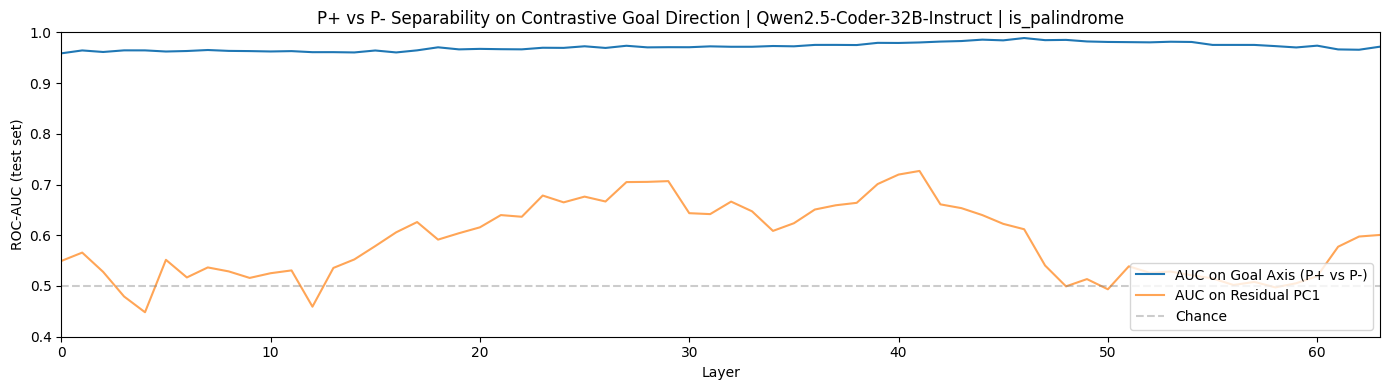

In [26]:
# ── AUC summary plot ──────────────────────────────────────────────────────────
layers_sorted_cd = sorted(cd_proj_results.keys())
auc_goal_vals  = [cd_proj_results[l]["auc_goal"]      for l in layers_sorted_cd]
auc_resid_vals = [cd_proj_results[l]["auc_residual"]  for l in layers_sorted_cd]

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(layers_sorted_cd, auc_goal_vals,  label="AUC on Goal Axis (P+ vs P-)", linewidth=1.5)
ax.plot(layers_sorted_cd, auc_resid_vals, label="AUC on Residual PC1", linewidth=1.5, alpha=0.7)
ax.axhline(y=0.5, color="gray", linestyle="--", alpha=0.4, label="Chance")
ax.set_xlabel("Layer")
ax.set_ylabel("ROC-AUC (test set)")
ax.set_title(
    f"P+ vs P- Separability on Contrastive Goal Direction | "
    f"{mt.name.split('/')[-1]} | {target_predicate.name}"
)
ax.legend(loc="lower right")
ax.set_ylim(0.4, 1.0)
ax.set_xlim(layers_sorted_cd[0], layers_sorted_cd[-1])
plt.tight_layout()
plt.savefig(os.path.join(FIGURE_DIR, "auc_summary.png"), dpi=150)
plt.show()


In [35]:

from typing import Literal
from sklearn.metrics import roc_auc_score

# Project test-set latents onto:
#   X-axis: Learned direction v   (goal axis)
#   Y-axis: Top PCA component of the residual (z − (z·v)v)

DIRECTION_TYPE: Literal["contrastive", "mean_diff"] = "mean_diff"
LAYER_STEP_ANIM = 4
DO_NORMALIZE = True

_dirs = contrastive_directions if DIRECTION_TYPE == "contrastive" else goal_directions
anim_layers = sorted(l for l in _dirs if l % LAYER_STEP_ANIM == 0)

# Recompute projections for the selected direction type
_proj: dict[int, dict] = {}
for l in anim_layers:
    v = _dirs[l].cpu().numpy()
    z_pos = Z_pos_by_layer[l][test_idx_arr].cpu().numpy()
    z_neg = Z_neg_by_layer[l][test_idx_arr].cpu().numpy()
    n_test = z_pos.shape[0]
    all_z = np.concatenate([z_pos, z_neg], axis=0)
    if DO_NORMALIZE:
        norms = np.maximum(np.linalg.norm(all_z, axis=1, keepdims=True), 1e-8)
        all_z = all_z / norms
    pg = all_z @ v
    zr = all_z - np.outer(pg, v)
    pr = PCA(n_components=1).fit_transform(zr).squeeze()
    labels = np.concatenate([np.ones(n_test), np.zeros(n_test)])
    _proj[l] = {
        "pos_goal":     pg[:n_test], "neg_goal":     pg[n_test:],
        "pos_residual": pr[:n_test], "neg_residual": pr[n_test:],
        "auc_goal":     roc_auc_score(labels, pg),
        "auc_residual": roc_auc_score(labels, pr),
    }

all_x = np.concatenate([np.concatenate([_proj[l]["pos_goal"],     _proj[l]["neg_goal"]])     for l in anim_layers])
all_y = np.concatenate([np.concatenate([_proj[l]["pos_residual"], _proj[l]["neg_residual"]]) for l in anim_layers])
pad_x = (all_x.max() - all_x.min()) * 0.05
pad_y = (all_y.max() - all_y.min()) * 0.05

fig, ax = plt.subplots(figsize=(8, 7))
neg_sc = ax.scatter([], [], alpha=0.25, s=8, c="tab:red",  label="P- (pursuing P−)")
pos_sc = ax.scatter([], [], alpha=0.25, s=8, c="tab:blue", label="P+ (pursuing P+)")
ax.legend(markerscale=4, loc="upper left")
ax.set_xlim(all_x.min() - pad_x, all_x.max() + pad_x)
ax.set_ylim(all_y.min() - pad_y, all_y.max() + pad_y)
ax.axvline(0, color="gray", linewidth=0.5, linestyle="--", alpha=0.4)
ax.axhline(0, color="gray", linewidth=0.5, linestyle="--", alpha=0.4)
ax.set_xlabel(f"Projection onto {DIRECTION_TYPE.replace('_', '-')} direction (v)")
ax.set_ylabel("Residual PC1  (z − (z·v)v)")
title = ax.set_title("")

def update(frame_idx):
    l = anim_layers[frame_idx]
    r = _proj[l]
    pos_sc.set_offsets(np.column_stack([r["pos_goal"], r["pos_residual"]]))
    neg_sc.set_offsets(np.column_stack([r["neg_goal"], r["neg_residual"]]))
    title.set_text(
        f"Layer {l} | {mt.name.split('/')[-1]} | {target_predicate.name} | {DIRECTION_TYPE}\n"
        f"AUC(goal)={r['auc_goal']:.3f}  AUC(resid)={r['auc_residual']:.3f}"
    )
    return pos_sc, neg_sc, title

anim2 = animation.FuncAnimation(fig, update, frames=len(anim_layers), interval=300, blit=False)
gif_name = f"goal_axis_residual_{DIRECTION_TYPE}.gif"
anim2.save(os.path.join(FIGURE_DIR, gif_name), writer="pillow", fps=2, dpi=120)
plt.close(fig)
rich_print(f"Saved [bold]{gif_name}[/bold] to {FIGURE_DIR}")
HTML(anim2.to_jshtml())


2026-03-02 13:41:23 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.PillowWriter'>


Saved goal_axis_residual_mean_diff.gif to /disk/u/arnab/Codes/Projects/goals/results/multi_probe/Qwen2.5-Coder-32B-Instruct/is_palindrome/figures

2026-03-02 13:41:26 matplotlib.animation INFO     Animation.save using <class 'matplotlib.animation.HTMLWriter'>
2026-03-02 13:41:26 matplotlib.animation DEBUG    frame size in pixels is 800 x 700
2026-03-02 13:41:27 matplotlib.animation DEBUG    MovieWriter: clearing temporary path=<TemporaryDirectory '/tmp/tmp66m18tc1'>


## Test Causality (Steering)

Steer the model with the learned P+ direction and check whether it shifts generation
toward implementing P+ first.  Since all orderings are correct (green), we evaluate
by checking which predicate's anchor token appears first in the steered generation —
not by unit tests.

`coeff > 0` steers toward P+ first; `coeff < 0` steers toward P- first.

In [162]:
from src.goals.functional import supports_chat_template, apply_chat_template
from src.functional import generate_with_patch, get_hs, PatchSpec
from src.tokens import prepare_input

# ── Select sample + build prompt ─────────────────────────────────────────────
SAMPLE_IDX = 0
sample = target_predicate.samples[SAMPLE_IDX]

# Use an inconsequential (unprefilled) prompt to see the model's natural preference
prefill = ""
if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=sample.instruction.strip() if hasattr(sample, "instruction") else "",
        incomplete_code=sample.code + prefill,
    )
else:
    prompt = sample.code + prefill

print(f'"Prompt (last 200 chars):\n...{prompt[-200:]}"')


"Prompt (last 200 chars):
...2 characters and is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return "


In [163]:
# ── Extract hidden state at last position for norm-scaling ───────────────────
tokenized = prepare_input(prompts=prompt, tokenizer=mt)
hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(mt.layer_name_format.format(l), -1) for l in range(mt.n_layer)],
)


In [164]:
# ── Load directions + build steering patches ─────────────────────────────────
loaded_directions = torch.load(
    os.path.join(save_dir, "contrastive_directions.pt"),
    map_location="cuda:0",
)

# Steer layers where test accuracy is highest — inspect auc_summary.png to pick range
layer_from = 30
layer_to   = 45
coeff      = 0.09  # positive = toward P+; negative = toward P-

steer_patches = []
for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig   = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx].to(h_orig.device)
    scaled   = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())
    steer_patches.append(
        PatchSpec(location=(layer_name, -1), patch=scaled, strategy="add", on_pass="all")
    )

rich_print(f"Steering layers {layer_from}–{layer_to - 1} with coeff={coeff}")


Steering layers 30–44 with coeff=0.09

In [165]:
from scripts.test_causality import generate_and_evaluate

# ── Generate baseline and steered outputs ────────────────────────────────────
N_GENERATIONS = 100
MAX_NEW_TOKENS = 64

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches = None,
    label = "testing"
)

2026-03-02 14:39:17 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-02 14:39:25 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-02 14:39:25 scripts.test_causality DEBUG    Evaluation done: 100/100 passed (1.000)


In [166]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    # if gen.eval.verdict == "PASSED"
][:5]
pretty_print_eval_results(eval_results_filtered)

"""def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
└───────────────────┴─────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 100/100 passed, 0/100 failed

In [167]:
steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=N_GENERATIONS,
    patches=steer_patches,
    label="steering"
)


2026-03-02 14:39:34 scripts.test_causality DEBUG    Generating 100 samples (steering)...


2026-03-02 14:39:41 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-02 14:39:41 scripts.test_causality DEBUG    Evaluation done: 76/100 passed (0.760)


In [168]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
]
pretty_print_eval_results(eval_results_filtered)

"""def is_valid_palindrome(s: str) -> bool:
    """Return True iff s has at least 2 characters and is a palindrome."""
    return """

                               Code Completion Results                               
┏━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill           ┃ Logic                           ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "" │ "2 <= len(s) and s == s[::-1]"  │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) > 1 and s == s[::-1]"  │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) > 1 and s == s[::-1]"  │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) > 1 and s == s[::-1]"  │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) >= 2 and s == s[::-1]" │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ "2 <= len(s) and s == s[::-1]"  │ PASSED  │            │      │
├───────────────────┼─────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "" │ " len(s) > 1 and s == 

Summary: 76/100 passed, 24/100 failed

In [170]:
# ── Evaluate: which predicate appears first? (anchor-token scoring) ───────────
from src.goals.anchor import _extract_boolean_expr, _split_clauses

baseline_outputs = [gen.lm_generation for gen in baseline_eval_results.generations]
steered_outputs = [gen.lm_generation for gen in steered_eval_results.generations]

p_plus_anchors = target_predicate.p_plus.anchor_tokens
p_minus_anchors = sample.p_minus.anchor_tokens if sample.p_minus else []


def predicate_order(text: str) -> str:
    """Return 'p_plus_first', 'p_minus_first', or 'unclear'."""
    full = sample.code + prefill + text
    result = _extract_boolean_expr(full)
    if result is None:
        # Fall back to raw anchor search
        p_plus_pos = min(
            (full.find(a) for a in p_plus_anchors if full.find(a) >= 0), default=None
        )
        p_minus_pos = min(
            (full.find(a) for a in p_minus_anchors if full.find(a) >= 0), default=None
        )
    else:
        expr, expr_start = result
        p_plus_pos = next(
            (expr.find(a) for a in p_plus_anchors if expr.find(a) >= 0), None
        )
        p_minus_pos = next(
            (expr.find(a) for a in p_minus_anchors if expr.find(a) >= 0), None
        )

    if p_plus_pos is None and p_minus_pos is None:
        return "unclear"
    if p_minus_pos is None:
        return "p_plus_first"
    if p_plus_pos is None:
        return "p_minus_first"
    return "p_plus_first" if p_plus_pos <= p_minus_pos else "p_minus_first"


from collections import Counter

baseline_orders = Counter(predicate_order(g) for g in baseline_outputs)
steered_orders = Counter(predicate_order(g) for g in steered_outputs)

rich_print(f"\nP+ anchors : {p_plus_anchors}")
rich_print(f"P- anchors : {p_minus_anchors}")
rich_print(f"\nBaseline predicate order: {dict(baseline_orders)}")
rich_print(f"Steered  predicate order: {dict(steered_orders)}")


def _rate(counter, key):
    total = sum(counter.values())
    return counter.get(key, 0) / total if total > 0 else 0.0


rich_print(
    f"\nP+ first rate: baseline={_rate(baseline_orders, 'p_plus_first'):.2f}  "
    f"steered={_rate(steered_orders, 'p_plus_first'):.2f}  "
    f"Δ={_rate(steered_orders, 'p_plus_first') - _rate(baseline_orders, 'p_plus_first'):+.2f}"
)


P+ anchors : ['== s.lower()[::-1]', '== s[::-1]', '[::-1]', '[::-2]', 'enumerate(s)', 'lower()[::-1]', 'reversed', 's != s[::-1]', 's ==', 's == s', 's == s[', 's == s[::-1]', 's.lower() ==', 's[-1:-3:-1]', 's[-i-1]', 's[::- 1]', 's[::-1]']

P- anchors : ['> 1', '>= 2', 'len(', 'len(s)']

Baseline predicate order: {'p_minus_first': 100}

Steered  predicate order: {'p_minus_first': 100}

P+ first rate: baseline=0.00  steered=0.00  Δ=+0.00

### Check goal persistance

In [119]:
from src.goals.data import IncompleteCodeDataset

single_pred_ds = IncompleteCodeDataset.load_dataset()
single_pred_idx = [
    idx
    for idx, single_sample in enumerate(single_pred_ds.samples)
    if single_sample.function_name == target_predicate.name
][0]
print(f"Selected sample idx: {single_pred_idx} / {len(single_pred_ds.samples)}")
single_pred_sample = single_pred_ds.samples[single_pred_idx]
print(f'"{single_pred_sample.code}"')


# prefill = "(3"
# prefill = "0 =="
# prefill = "1 +"
prefill = "1 -"
# prefill = "1 - len(s)"
# prefill = "1"
# prefill = ""
# prefill = "5"
# prefill = "("
# prefill = "3 +"

if supports_chat_template(mt):
    prompt = apply_chat_template(
        mt=mt,
        user_query=single_pred_sample.instruction.strip(),
        incomplete_code=single_pred_sample.code + prefill,
    )
else:
    prompt = single_pred_sample.instruction + "<code>" + single_pred_sample.code + prefill

print(f"Prompt:\n{prompt}")

2026-03-02 14:21:07 src.goals.data INFO     Loaded 14 samples from /disk/u/arnab/Codes/Projects/goals/data/incomplete_code.json
Selected sample idx: 5 / 14
"def is_palindrome(s: str) -> bool:
    return True if "
Prompt:
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a function in python that checks if a string is a palindrome.<|im_end|>
<|im_start|>assistant
<code>
def is_palindrome(s: str) -> bool:
    return True if 1 -


In [120]:
tokenized = prepare_input(
    prompts=prompt,
    tokenizer=mt,
)

hs = get_hs(
    mt=mt,
    input=tokenized,
    locations=[(layer_name, -1) for layer_name in mt.layer_names],
)

In [121]:
from scripts.test_causality import generate_and_evaluate

baseline_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches = None,
    label = "testing"
)

2026-03-02 14:21:09 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-02 14:21:15 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-02 14:21:15 scripts.test_causality DEBUG    Evaluation done: 1/100 passed (0.010)


In [123]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(baseline_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                        Code Completion Results                                        
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill              ┃ Logic                                          ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "1 -" │ "1 - len(s) == (len(s) - 1) else s == s[::-1]" │ PASSED  │            │      │
└──────────────────────┴────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 1/100 passed, 99/100 failed

In [127]:
# ── Load directions + build steering patches ─────────────────────────────────

model_short_name = mt.name.split("/")[-1]
# save_dir = os.path.join(
#     env_utils.DEFAULT_RESULTS_DIR,
#     ############################################################
#     # "multi_probe",
#     "probes_unique",
#     ############################################################
#     model_short_name,
#     f"sample_{single_pred_idx}",
# )

save_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multi_probe",
    model_short_name,
    target_predicate.name
)

loaded_directions = torch.load(
    os.path.join(save_dir, "contrastive_directions.pt"),
    map_location="cuda:0",
)

# Steer layers where test accuracy is highest — inspect auc_summary.png to pick range
layer_from = 40
layer_to = 50
coeff = 0.08  # positive = toward P+; negative = toward P-

steer_patches = []
for layer_idx in range(layer_from, layer_to):
    layer_name = mt.layer_name_format.format(layer_idx)
    h_orig = hs[(layer_name, -1)]
    goal_dir = loaded_directions[layer_idx].to(h_orig.device)
    scaled = goal_dir * coeff * (h_orig.norm() / goal_dir.norm())

    print(
        f"layer={layer_idx} >> |h_orig|={h_orig.norm()}, |goal_dir|={goal_dir.norm()}, |scaled|={scaled.norm()}"
    )

    steer_patches.append(
        PatchSpec(
            location=(layer_name, -1), patch=scaled, strategy="add", on_pass="all"
        )
    )

rich_print(f"Steering layers {layer_from}–{layer_to - 1} with coeff={coeff}")


layer=40 >> |h_orig|=298.0, |goal_dir|=0.9999999403953552, |scaled|=23.840002059936523
layer=41 >> |h_orig|=306.0, |goal_dir|=1.0, |scaled|=24.479999542236328
layer=42 >> |h_orig|=304.0, |goal_dir|=0.9999999403953552, |scaled|=24.31999969482422
layer=43 >> |h_orig|=310.0, |goal_dir|=1.0, |scaled|=24.799999237060547
layer=44 >> |h_orig|=314.0, |goal_dir|=1.0, |scaled|=25.1200008392334
layer=45 >> |h_orig|=322.0, |goal_dir|=1.0, |scaled|=25.760000228881836
layer=46 >> |h_orig|=342.0, |goal_dir|=0.9999999403953552, |scaled|=27.360002517700195
layer=47 >> |h_orig|=364.0, |goal_dir|=1.0, |scaled|=29.119998931884766
layer=48 >> |h_orig|=380.0, |goal_dir|=0.9999999403953552, |scaled|=30.399999618530273
layer=49 >> |h_orig|=416.0, |goal_dir|=0.9999999403953552, |scaled|=33.279998779296875


Steering layers 40–49 with coeff=0.08

In [128]:
from scripts.test_causality import generate_and_evaluate

steered_eval_results = generate_and_evaluate(
    mt=mt,
    sample=single_pred_sample,
    prefill=prefill,
    prompt=prompt,
    n_generations=100,
    patches=steer_patches,
    label="testing",
)

2026-03-02 14:29:24 scripts.test_causality DEBUG    Generating 100 samples (testing)...


2026-03-02 14:29:31 scripts.test_causality DEBUG    Generation done. Evaluating 100 outputs...
2026-03-02 14:29:31 scripts.test_causality DEBUG    Evaluation done: 3/100 passed (0.030)


In [129]:
from src.goals.eval import pretty_print_eval_results
from copy import deepcopy

eval_results_filtered = deepcopy(steered_eval_results)
eval_results_filtered.generations = [
    gen for gen in eval_results_filtered.generations 
    if gen.eval.verdict == "PASSED"
]
pretty_print_eval_results(eval_results_filtered)

"""def is_palindrome(s: str) -> bool:
    return True if """

                                               Code Completion Results                                               
┏━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━┓
┃ Prefill              ┃ Logic                                                        ┃ Verdict ┃ Unit Tests ┃ Logs ┃
┡━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━┩
│ steering_eval: "1 -" │ "1 - len(s[::-1]) == 0 else False if s != s[::-1] else True" │ PASSED  │            │      │
├──────────────────────┼──────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s[::-1]) == 0 else s == s[::-1]"                    │ PASSED  │            │      │
├──────────────────────┼──────────────────────────────────────────────────────────────┼─────────┼────────────┼──────┤
│ steering_eval: "1 -" │ "1 - len(s[::-1]) == 0 else s == s[::-1]"                    │ PASSED  │            │      │
└──────────────────────┴──────────────────────────────────────────────────────────────┴─────────┴────────────┴──────┘

Summary: 3/100 passed, 97/100 failed

In [6]:
def is_lower(s: str) -> bool:
    return all(c in "abcdefghijklmnopqrstuvwxyz " for c in s)

is_lower("hello wOrld")  # True

False